# TTK4115 — Helicopter Lab 4: Kalman filter

**Part IV-only dataset — based on fourth audit (7 November 2026)** (2026 lab assignment, Part IV).

This notebook is structured according to the lab's numbered tasks. It reads MATLAB `.mat` files **directly from a ZIP archive**, so no directory restructuring or MATLAB installation is needed.

### Setup
Place **`Del 4.zip`** (the original lab archive) or **`Lab4_data.zip`** (the smaller companion data archive) next to this notebook. Install Python packages if needed:

```bash
pip install numpy scipy matplotlib pandas jupyter
```

Run **Kernel → Restart & Run All**. Change the configuration cell if you want another experiment, shorter time windows, or more PNG exports. The notebook writes publication-ready `.png` and `.pdf` figure files to `figures_lab4/`.

> **Interpretation limits:** Recordings were made under different joystick trajectories and may include transients; therefore RMS errors between different experiments are **descriptive, not controlled comparisons**. Numeric labels inferred from filenames do not prove the exact Simulink runtime values. Some Task 1 recordings use **different signals and units** and cannot be compared as if they had the same six channels. Figures distinguish physical measurements, observer estimates, and encoder data.

**Verified revision (2026-11-05):** All core Lab 4 recordings are plotted by default, an automatic coverage audit is included at the end, and potentially ambiguous axes are explicitly flagged.


When using the **original `Del 4.zip`**, the notebook also checks repeated basenames between the two lab folders. It plots the two **non-identical older Lab 4 recordings** separately. `Lab4_data.zip` does not contain those older alternatives.


**Third-pass validation:** startup-zero screening; sensitivity of sample covariance to time windows; explicit distinction between finite fractions over the entire recording and RMSE computed from $t\geq2\,\mathrm{s}$.


**Fourth audit additions:** IMU serial dependence, explicit grounded raw covariance, within-run measurement/estimate error comparisons (no cross-run causal ranking), log error growth on independent update/no-update trials, and a traceable physical-parameter check. The historical measurements are not modified.


**Limitations:** These analyses were initially developed using the previous combined archive. Unknown sensor channels remain labeled as unverified. Previous exported figures should be treated as exploratory results and checked against the original signals before use in the final report.


## 0. Configuration, data inventory, and helper functions

In [22]:
from pathlib import Path
from io import BytesIO
import zipfile, re, warnings

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 115, "savefig.dpi": 180, "axes.grid": True,
    "grid.alpha": 0.25, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "figure.constrained_layout.use": True,
})

HERE = Path.cwd()
ZIP_CHOICES = [HERE.parent / "02_Verifiserte_Data" / "TTK4115_Part4_Renset_Data_Verifisert.zip", HERE / "TTK4115_Part4_Renset_Data_Verifisert.zip"]
DATA_ZIP = next((p for p in ZIP_CHOICES if p.is_file()), None)
if DATA_ZIP is None:
    raise FileNotFoundError("Place the verified Part IV ZIP in ../02_Verifiserte_Data/ or alongside the notebook.")
OUT = HERE / "figures_lab4"
OUT.mkdir(exist_ok=True)

# Edit these values to examine individual segments / experiments.
PREFERRED_FOLDER = "Data/Task_4_"
T_START = None                  # e.g. 5.0; None means beginning
T_END = None                    # e.g. 30.0; None means end
SHOW_MAX_POINTS = 4000         # plot decimation; never changes raw measurements
EXPORT_PDF = True
EXPORT_ALL_CASES = True        # automatically plot ALL 11 complete Qd/update-mode cases
EXPORT_TASK42_TUNING = True    # automatically plot ALL additional Task 4.2 recordings
SELECTED_QD = "qdemin6"       # qd0, qdemin6, qdemin4, qde1, qde34, qdinf (where present)
SELECTED_MODE = "newdata"     # newdata or nonewdata

STATE_NAMES = [r"Pitch $p$", r"Pitch rate $\dot p$", r"Elevation $e$",
               r"Elevation rate $\dot e$", r"Travel $\lambda$", r"Travel rate $\dot\lambda$"]
STATE_UNITS = ["rad", "rad/s", "rad", "rad/s", "rad", "rad/s"]
STATE_LABELS = ["p", "p_dot", "e", "e_dot", "lambda", "lambda_dot"]

archive = zipfile.ZipFile(DATA_ZIP)
files_in_zip = [s for s in archive.namelist() if s.lower().endswith(".mat")]
print(f"Archive: {DATA_ZIP.name} | MAT files: {len(files_in_zip)}")

def match_path(name):
    if name in files_in_zip: return name  # allow exact archive member for non-identical older recordings
    hits = [p for p in files_in_zip if p.rsplit("/", 1)[-1].lower() == name.lower()]
    if not hits:
        raise FileNotFoundError(f"No recording named {name!r}. Check archive listing below.")
    return next((h for h in hits if PREFERRED_FOLDER.lower() in h.lower()), hits[0])

_cache = {}
def read_mat(name):
    """Return (time[N], channels[C,N]) from a QuaRC/Simulink array recording."""
    if name not in _cache:
        path = match_path(name)
        raw = sio.loadmat(BytesIO(archive.read(path)), squeeze_me=False)
        fields = [(k,v) for k,v in raw.items() if not k.startswith("__")]
        if len(fields) != 1:
            raise ValueError(f"Unexpected MATLAB variables in {path}: {[x[0] for x in fields]}")
        matrix = np.asarray(fields[0][1], dtype=float)
        if matrix.ndim != 2 or matrix.shape[0] < 2:
            raise ValueError(f"Unsupported signal shape {matrix.shape} in {path}")
        t, y = matrix[0].copy(), matrix[1:].copy()
        if t.size > 1 and np.any(np.diff(t) <= 0):
            raise ValueError(f"Time not increasing in {path}")
        _cache[name] = (t, y)
    return _cache[name]

def view(t, values, start=T_START, end=T_END):
    ok = (np.ones(t.size, bool) if start is None else t >= start)
    if end is not None: ok &= t <= end
    ii = np.flatnonzero(ok)
    if ii.size == 0:
        raise ValueError(f"No points in time range {start} to {end} s")
    ii = ii[::max(1, int(np.ceil(ii.size / SHOW_MAX_POINTS)))]
    return t[ii], values[:, ii]

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    if EXPORT_PDF: fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    print(f"Figure exported: {name} (.png{', .pdf' if EXPORT_PDF else ''})")

def plot_channels(recording, title, labels=None, ncols=2, save=None, show=True):
    t, data = read_mat(recording)
    tx, dx = view(t, data)
    n = len(data)
    cols = min(ncols, n); rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6.8*cols, 2.85*rows), sharex=True, squeeze=False)
    for i, ax in enumerate(axes.flat):
        if i >= n: ax.set_visible(False); continue
        ax.plot(tx, dx[i], lw=0.85)
        ax.set_ylabel(labels[i] if labels else f"Channel {i+1} [unit unverified]")
        ax.set_xlabel("Time [s]")
    fig.suptitle(title, weight="bold")
    if save: save_fig(fig, save)
    if show: plt.show()
    else: plt.close(fig)

inventory = []
for path in sorted(files_in_zip):
    if PREFERRED_FOLDER.lower() not in path.lower() and "Task 3 og firevi" in " ".join(archive.namelist()):
        continue
    name = path.rsplit("/", 1)[-1]
    t, y = read_mat(name)
    inventory.append((name, y.shape[0], y.shape[1], round(float(t[-1]), 2),
                      round(100*np.isfinite(y).mean(), 3)))
inventory_df = pd.DataFrame(inventory, columns=["MAT filename", "channels", "samples", "duration [s]", "finite [%]"])
display(inventory_df)

Archive: TTK4115_Part4_Renset_Data_Verifisert.zip | MAT files: 47


,MAT filename,channels,samples,duration [s],finite [%]
0,task41_xhat_noie_fligh__older_v1.mat,6,8083,16.16,100.0
1,task41_noice_grounded.mat,10,19211,38.42,100.0
2,task41_xhat_noie_fligh.mat,6,9921,19.84,100.0
3,task41_xhat_noie_flight.mat,5,10757,21.51,100.0
4,task41_xhat_noie_grounded.mat,6,28049,56.10,100.0
5,task42_qvtuningqv10emin6__older_v1.mat,6,32701,65.40,100.0
6,task42_newdata_encodervalues.mat,6,50522,101.04,100.0
7,task42_newdata_xhatvalues.mat,6,50522,101.04,100.0
8,task42_newdata_yvalues.mat,6,50522,101.04,100.0
9,task42_qvtuning.mat,6,38533,77.06,100.0


## 4.1 — Task 1: Measurement-noise estimation

**Assignment:** Record the helicopter on the ground and while hovering near the linearization point. Compare measurement noise and estimate its covariance. The assignment asks to use the **in-flight measurement covariance** as \(R_d\).

**Verified file-format caveat:** `task41_xhat_noie_grounded.mat` has six non-time channels that look like *raw accelerometer/gyro measurements* (one acceleration is close to gravity). `task41_xhat_noie_fligh.mat` has six channels in state-like coordinates. The similarly named `task41_xhat_noie_flight.mat` has **five** non-time channels and must be plotted separately, without assuming the same state ordering. `task41_noice_grounded.mat` has ten channels, including constant zero channels. Thus, the provided ground and flight recordings **must not be subtracted or compared channel-by-channel without checking their origins and coordinate transformations**.

The latest MATLAB initialization script explicitly computes `Rd = cov(X_meas')` from `task41_xhat_noie_fligh.mat`. We reproduce that computation below, but it contains **physical motion as well as sensor noise** if the helicopter moved. Use a stationary segment when possible and document the selected window.

**Signal provenance:** The current `heli_q8.slx` Mux2 records encoder states as \(p,\dot p,e,\dot e,\lambda,\dot\lambda\). The IMU module exposes accelerometer (m/s²) and gyro (rad/s) vectors; the six grounded raw-channel identities are **inferred** from magnitudes rather than proven from the saved MAT file. The 10-channel file has no verified channel mapping.


**Third-pass quality control:** The grounded six-channel file has leading zero samples before the IMU is initialized; exclude at least the first second for grounded noise statistics. The in-flight dataset shows nonstationary helicopter motion and encoder travel drift, so the full-record covariance below reproduces the MATLAB-script calculation but **cannot be interpreted as a clean IMU measurement-noise covariance** without a stationary window and further validation.


Figure exported: 41_grounded_raw (.png, .pdf)


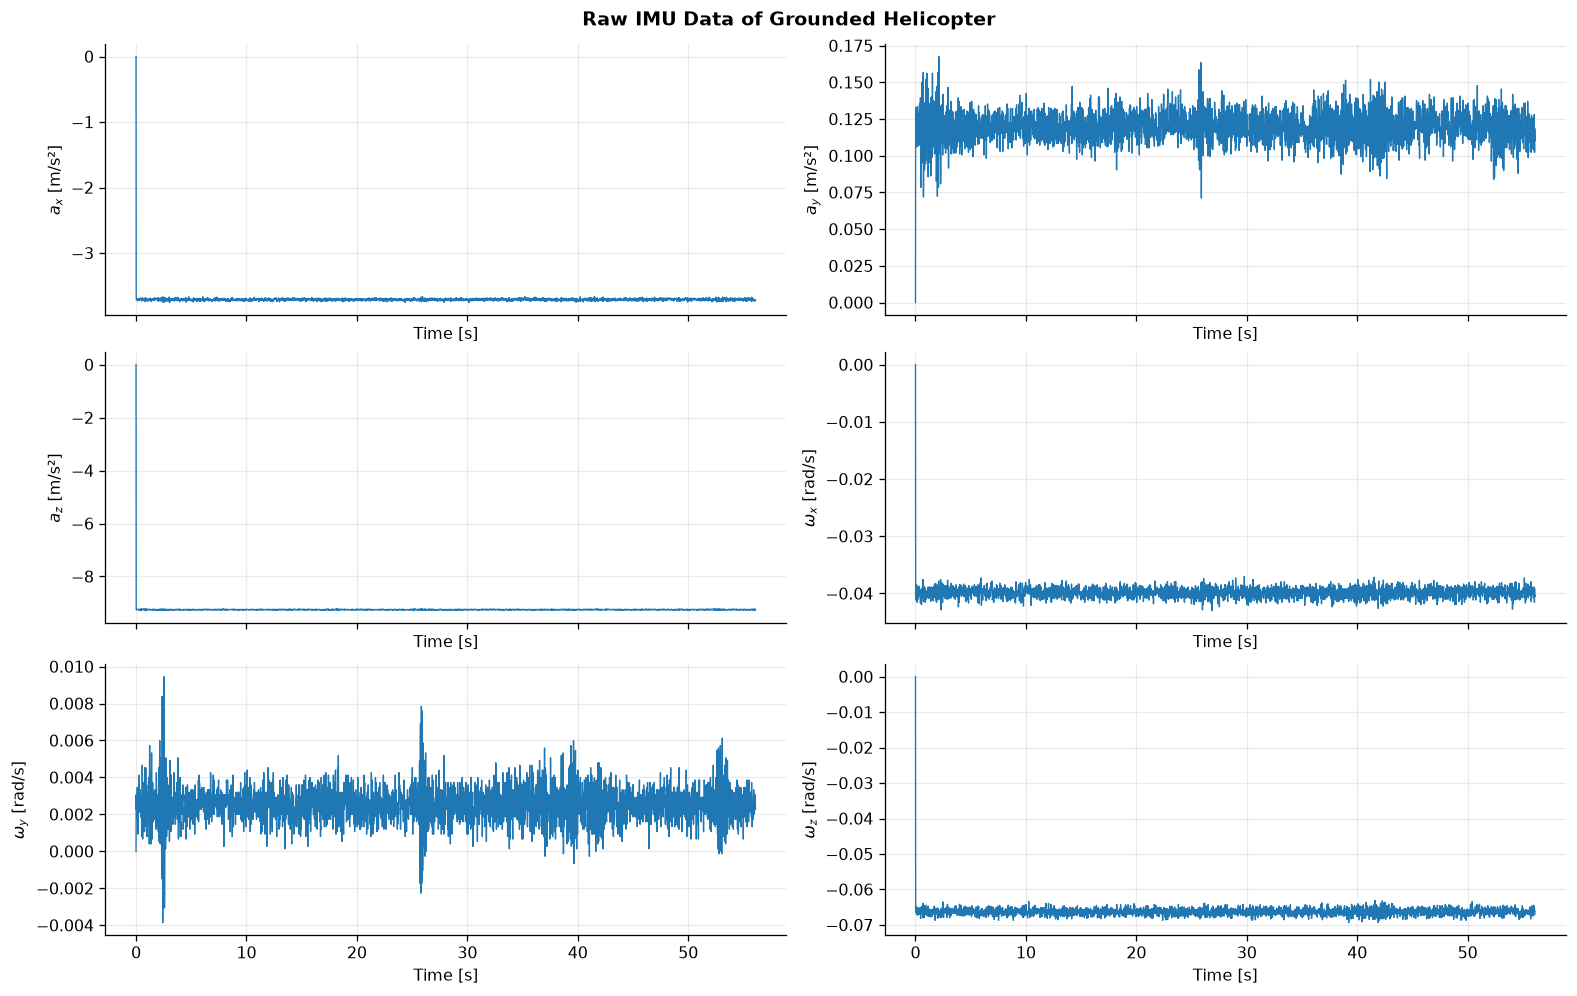

Figure exported: 41_flight_recording (.png, .pdf)


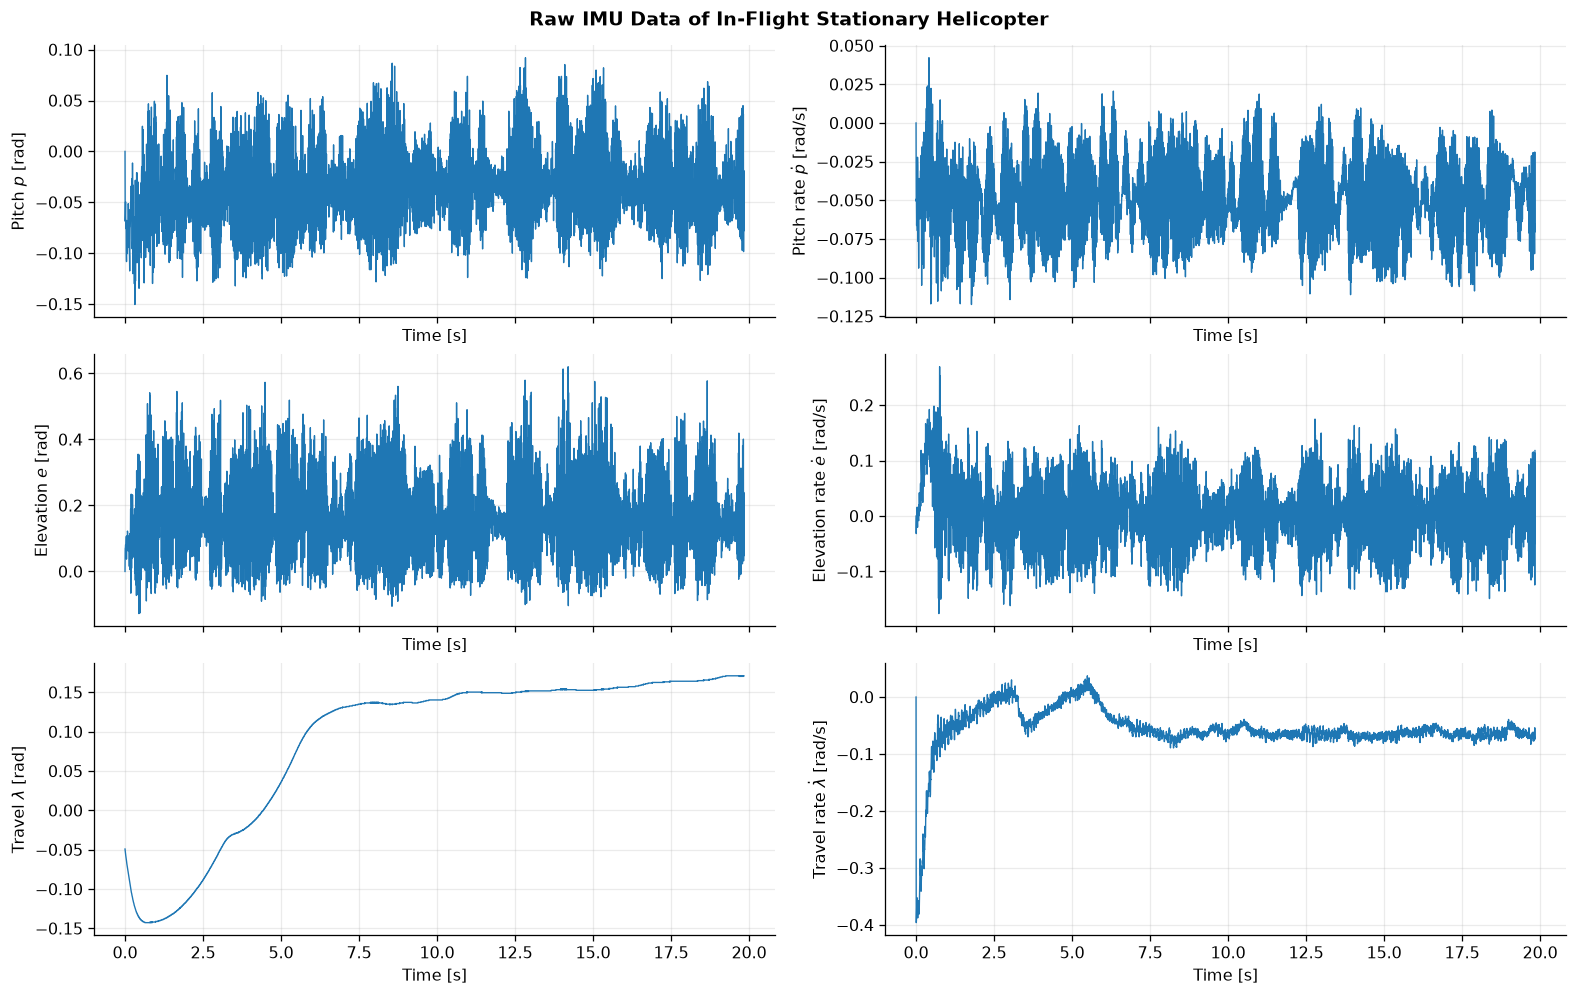

In [23]:
raw_ground = "task41_xhat_noie_grounded.mat"
flight_meas = "task41_xhat_noie_fligh.mat"

plot_channels(raw_ground, "Raw IMU Data of Grounded Helicopter",
              ["$a_x$ [m/s²]", "$a_y$ [m/s²]", "$a_z$ [m/s²]",
               r"$\omega_x$ [rad/s]", r"$\omega_y$ [rad/s]", r"$\omega_z$ [rad/s]"],
              save="41_grounded_raw")
plot_channels(flight_meas, "Raw IMU Data of In-Flight Stationary Helicopter",
              [f"{s} [{u}]" for s,u in zip(STATE_NAMES,STATE_UNITS)],
              save="41_flight_recording")

,Channel,Flight sample variance (motion included),Flight sample standard deviation
0,p,0.001745,0.041772
1,p_dot,0.000682,0.026123
2,e,0.018749,0.136928
3,e_dot,0.004092,0.063968
4,lambda,0.010143,0.100715
5,lambda_dot,0.001816,0.042610


R_d from 9921 samples, time window [0.000, 19.840] s
Grounded raw IMU covariance uses t >= 1.0 s (startup zeros excluded).
Ground raw covariance is computed separately but NOT compared entry-by-entry with Rd (different units).
Full estimated Rd (from in-flight sample covariance):
 [[ 1.74489e-03  6.13176e-04  3.20439e-03 -2.03201e-03  6.17093e-04
   1.42348e-04]
 [ 6.13176e-04  6.82435e-04 -3.85379e-04 -9.50149e-04  1.26256e-05
   6.75079e-06]
 [ 3.20439e-03 -3.85379e-04  1.87491e-02 -4.34202e-03  3.55013e-05
   5.26766e-04]
 [-2.03201e-03 -9.50149e-04 -4.34202e-03  4.09191e-03 -7.45877e-04
  -4.32920e-04]
 [ 6.17093e-04  1.26256e-05  3.55013e-05 -7.45877e-04  1.01435e-02
  -2.49781e-04]
 [ 1.42348e-04  6.75079e-06  5.26766e-04 -4.32920e-04 -2.49781e-04
   1.81563e-03]]
Figure exported: 41_covariance_correlation (.png, .pdf)


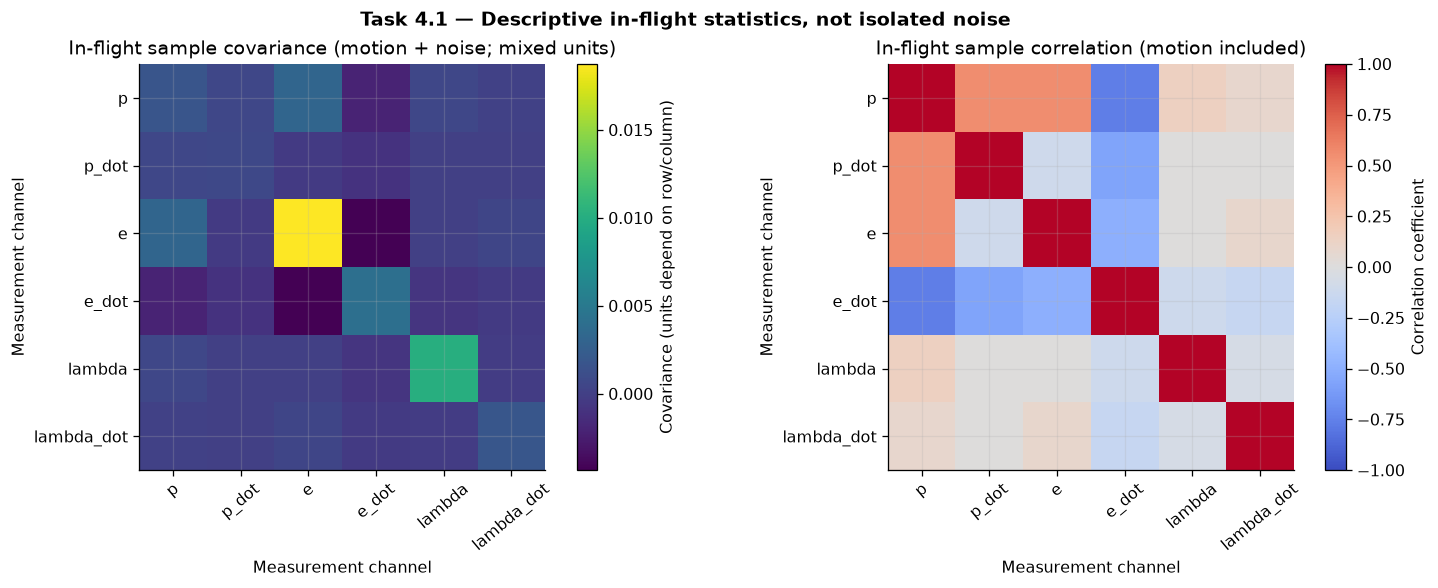

In [24]:
# Choose an approximately stationary segment; whole time range reproduces the MATLAB script.
RD_WINDOW = (None, None)  # e.g. (5.0, 9.0) if justified by the time-series plot

def covariance_window(recording, window=(None,None)):
    t, y = read_mat(recording)
    mask = np.ones(t.shape, dtype=bool)
    a,b = window
    if a is not None: mask &= t >= a
    if b is not None: mask &= t <= b
    mask &= np.all(np.isfinite(y), axis=0)
    if mask.sum() < 10: raise ValueError("Insufficient samples")
    return np.cov(y[:, mask], rowvar=True, ddof=1), y[:, mask], t[mask]

Rd, flight_data, t_flight = covariance_window(flight_meas, RD_WINDOW)
GROUND_START = 1.0  # exclude startup zeros in grounded raw IMU capture
raw_cov, ground_data, t_ground = covariance_window(raw_ground, (GROUND_START, None))
assert Rd.shape == (6, 6)
report = pd.DataFrame({
    "Channel": STATE_LABELS,
    "Flight sample variance (motion included)": np.diag(Rd),
    "Flight sample standard deviation": np.sqrt(np.diag(Rd)),
})
display(report)
print(f"R_d from {len(t_flight)} samples, time window [{t_flight[0]:.3f}, {t_flight[-1]:.3f}] s")
print(f"Grounded raw IMU covariance uses t >= {GROUND_START:.1f} s (startup zeros excluded).")
print("Ground raw covariance is computed separately but NOT compared entry-by-entry with Rd (different units).")
print("WARNING: the full in-flight sample covariance includes real motion and travel drift; it is not pure noise.")
print("Full estimated Rd (from in-flight sample covariance):\n", np.array2string(Rd, precision=5, suppress_small=False))
pd.DataFrame(Rd, index=STATE_LABELS, columns=STATE_LABELS).to_csv(OUT / "41_Rd_estimated.csv")
report.to_csv(OUT / "41_noise_variances.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(Rd)
axes[0].set_title("In-flight sample covariance (motion + noise; mixed units)")
axes[0].set_xticks(range(6), STATE_LABELS, rotation=40)
axes[0].set_yticks(range(6), STATE_LABELS)
axes[1].imshow(np.corrcoef(flight_data), vmin=-1, vmax=1, cmap="coolwarm")
axes[1].set_title("In-flight sample correlation (motion included)")
axes[1].set_xticks(range(6), STATE_LABELS, rotation=40)
axes[1].set_yticks(range(6), STATE_LABELS)
for ax in axes:
    ax.set_xlabel("Measurement channel")
    ax.set_ylabel("Measurement channel")
for ax, img in zip(axes, [axes[0].images[0], axes[1].images[0]]):
    fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04,
                 label="Covariance (units depend on row/column)" if ax is axes[0] else "Correlation coefficient")
fig.suptitle("Task 4.1 — Descriptive in-flight statistics, not isolated noise", weight="bold")
save_fig(fig,"41_covariance_correlation")
plt.show()
# Grounded RAW IMU covariance, separately identified (different units than the flight-state vector).
RAW_IMU_NAMES = ["a_x", "a_y", "a_z", "gyro_x", "gyro_y", "gyro_z"]
pd.DataFrame(raw_cov, index=RAW_IMU_NAMES, columns=RAW_IMU_NAMES).to_csv(OUT / "41_grounded_raw_covariance.csv")


### 4.1.1 — Stationarity and initialization audit

Before interpreting the full-record covariance as the measurement-noise matrix, **exclude invalid startup samples and verify that the helicopter was approximately stationary**. The next code cell quantifies how much the computed standard deviations change with the time window. The illustrative 10–15 s flight window is **not automatically validated as stationary**; it is included to reveal sensitivity, not to select a definitive $R_d$. Ground acceleration channels and flight state-like channels have different units, so they must **not** be compared entry-by-entry.

,Source,Channel,Unit,Window A,Window B,Std A,Std B,Std ratio A/B
0,task41_xhat_noie_grounded.mat,1,m/s²,full grounded recording,grounded t>=1 s,0.040582,0.013232,3.067016
1,task41_xhat_noie_grounded.mat,2,m/s²,full grounded recording,grounded t>=1 s,0.010108,0.009880,1.023053
2,task41_xhat_noie_grounded.mat,3,m/s²,full grounded recording,grounded t>=1 s,0.096112,0.008952,10.735844
3,task41_xhat_noie_grounded.mat,4,rad/s,full grounded recording,grounded t>=1 s,0.000919,0.000819,1.121611
4,task41_xhat_noie_grounded.mat,5,rad/s,full grounded recording,grounded t>=1 s,0.000948,0.000947,1.001207
5,task41_xhat_noie_grounded.mat,6,rad/s,full grounded recording,grounded t>=1 s,0.001108,0.000869,1.275505
6,task41_xhat_noie_fligh.mat,1,rad,full in-flight recording,in-flight t=10–15 s (illustrative),0.041772,0.040129,1.040930
7,task41_xhat_noie_fligh.mat,2,rad/s,full in-flight recording,in-flight t=10–15 s (illustrative),0.026123,0.025786,1.013071
8,task41_xhat_noie_fligh.mat,3,rad,full in-flight recording,in-flight t=10–15 s (illustrative),0.136928,0.136970,0.999690
9,task41_xhat_noie_fligh.mat,4,rad/s,full in-flight recording,in-flight t=10–15 s (illustrative),0.063968,0.058047,1.102007


Figure exported: 41_stationarity_sensitivity (.png, .pdf)


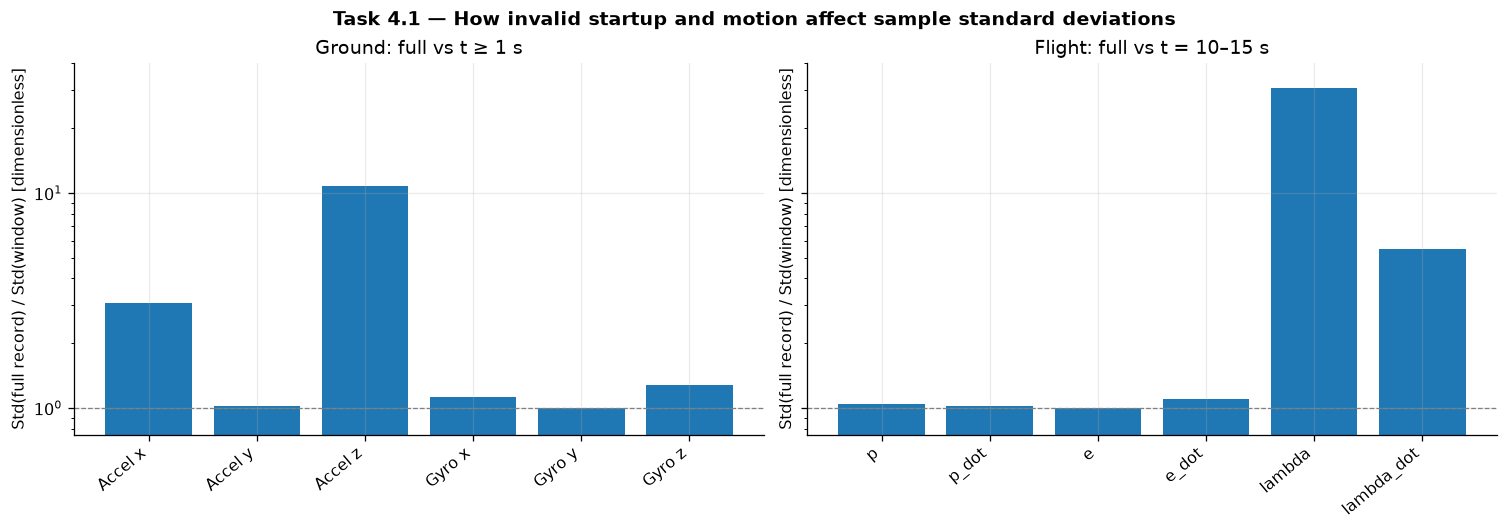

Extra grounded recording first nonzero data: t = 15.922 s


In [25]:
# Compare descriptive standard deviations to expose startup and motion contamination.
# These are different physical signal sets; never compare ground vs flight channel by channel.
ground_full_cov, _gr0, _tgr0 = covariance_window(raw_ground)
ground_clean_cov, _gr1, _tgr1 = covariance_window(raw_ground, (1.0, None))
flight_full_cov, _fl0, _tfl0 = covariance_window(flight_meas)
flight_slice_cov, _fl1, _tfl1 = covariance_window(flight_meas, (10.0, 15.0))

qc_rows = []
for recording, unit_labels, cov_a, cov_b, label_a, label_b in [
    (raw_ground, ["m/s²"]*3+["rad/s"]*3, ground_full_cov, ground_clean_cov,
     "full grounded recording", "grounded t>=1 s"),
    (flight_meas, STATE_UNITS, flight_full_cov, flight_slice_cov,
     "full in-flight recording", "in-flight t=10–15 s (illustrative)"),
]:
    for k in range(6):
        qc_rows.append({"Source":recording, "Channel":k+1, "Unit":unit_labels[k],
            "Window A":label_a, "Window B":label_b,
            "Std A":float(np.sqrt(cov_a[k,k])), "Std B":float(np.sqrt(cov_b[k,k])),
            "Std ratio A/B":float(np.sqrt(cov_a[k,k]/cov_b[k,k])) if cov_b[k,k]>0 else np.nan})
stationarity = pd.DataFrame(qc_rows)
stationarity.to_csv(OUT/"41_stationarity_sensitivity.csv",index=False)
display(stationarity)

# Dimensionless within-channel ratios avoid comparing channels with different physical units.
fig, ax = plt.subplots(1, 2, figsize=(13,4.5),sharey=True)
for a, names, cov_a, cov_b in [
    (ax[0], [f"Accel {s}" for s in ["x","y","z"]]+[f"Gyro {s}" for s in ["x","y","z"]],
     ground_full_cov,ground_clean_cov),
    (ax[1],STATE_LABELS,flight_full_cov,flight_slice_cov),
]:
    ratio = np.sqrt(np.diag(cov_a)/np.diag(cov_b))
    a.bar(range(6),ratio)
    a.axhline(1,color='gray',lw=.8,linestyle='--')
    a.set_xticks(range(6),names,rotation=40,ha="right")
    a.set_ylabel("Std(full record) / Std(window) [dimensionless]")
    a.set_yscale("log")
    a.set_ylim(.75,max(40,float(np.nanmax(ratio))*1.15))
ax[0].set_title("Ground: full vs t ≥ 1 s")
ax[1].set_title("Flight: full vs t = 10–15 s")
fig.suptitle("Task 4.1 — How invalid startup and motion affect sample standard deviations",weight="bold")
save_fig(fig,"41_stationarity_sensitivity")
plt.show()

# The extra 10-channel file is exactly zero for a long initial interval, not proof of zero noise.
t_extra, y_extra = read_mat("task41_noice_grounded.mat")
active = np.flatnonzero(np.any(y_extra != 0, axis=0))
print("Extra grounded recording first nonzero data:",
      f"t = {t_extra[active[0]]:.3f} s" if active.size else "all zero")


### Task 4.1 — Additional raw recording (inspect before using it)

This file has **10 channels**, and some are constant zero. The recording cannot automatically be treated as a 6-state IMU measurement. Display all channels to determine whether any steady segment could support a separate noise calculation.

The five-channel `task41_xhat_noie_flight.mat` is also included below. Its number of signals does not match the six-channel Kalman state vector, so no six-state labeling is imposed.


The additional 10-channel file is exactly zero on every channel until approximately **15.922 s**, and four channels remain identically zero. This does not demonstrate low sensor noise; it indicates non-informative/unused channels or a recording configuration that needs confirmation.


In [26]:
# plot_channels("task41_noice_grounded.mat",
#               "Task 4.1 — Additional grounded recording (channel identity unverified)",
#               save="41_extra_grounded")

# plot_channels("task41_xhat_noie_flight.mat",
#               "Task 4.1 — Additional in-flight 5-channel recording (identity unverified)",
#               save="41_additional_flight_5ch")


### 4.1.2 — Autocorrelation and repeated IMU samples

The lab handout mentions autocorrelation. The 2 ms Simulink grid is **not** necessarily the IMU's independent measurement rate: samples may be held/repeated between IMU updates. Autocorrelation here is descriptive, and can also arise from actual movement, estimator transformations, drift or low-frequency disturbances. The flight 10–15 s segment is **illustrative, not verified stationary**, and the ground and flight channels are not dimensionally interchangeable.

Figure exported: 41_autocorrelation (.png, .pdf)


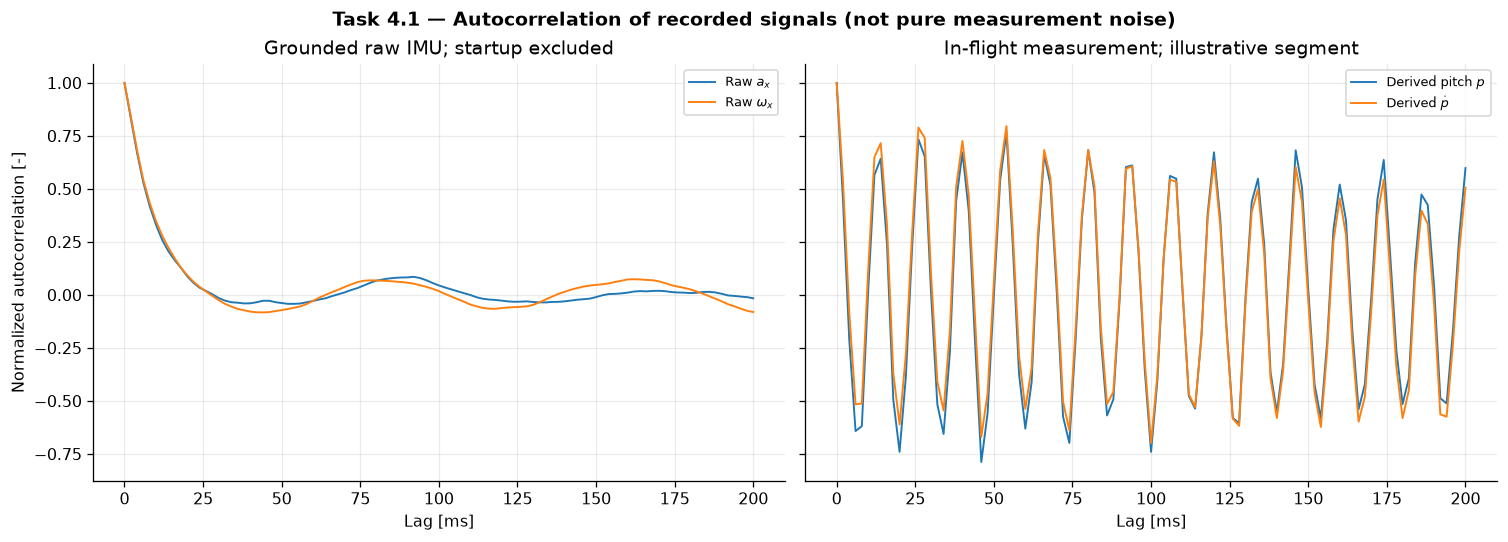

In [27]:
from scipy.signal import correlate

def normalized_acf(x, max_lag=100):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    x = x - np.mean(x)
    if len(x) < max_lag+10 or np.dot(x,x) <= 0:
        return np.full(max_lag+1, np.nan)
    corr = correlate(x,x,mode="full",method="fft")
    result = corr[len(x)-1:len(x)+max_lag] / np.dot(x,x)
    return result

fig,axs = plt.subplots(1,2,figsize=(13,4.6),sharey=True)
for ax, recording, window, channel_specs, ttl in [
    (axs[0],raw_ground,(1.0,None),[(0,r"Raw $a_x$"),(3,r"Raw $\omega_x$")],"Grounded raw IMU; startup excluded"),
    (axs[1],flight_meas,(10.0,15.0),[(0,r"Derived pitch $p$"),(1,r"Derived $\dot p$")],"In-flight measurement; illustrative segment"),
]:
    tt,yy=read_mat(recording)
    mask=np.ones(len(tt),dtype=bool)
    if window[0] is not None: mask &= tt>=window[0]
    if window[1] is not None: mask &= tt<=window[1]
    ts=float(np.median(np.diff(tt)))
    lag=np.arange(101)*ts*1000
    for idx,label in channel_specs:
        acf=normalized_acf(yy[idx,mask],100)
        ax.plot(lag,acf,label=label,lw=1.2)
    ax.set_xlabel("Lag [ms]")
    ax.set_title(ttl)
    ax.legend(fontsize=8)
axs[0].set_ylabel("Normalized autocorrelation [-]")
fig.suptitle("Task 4.1 — Autocorrelation of recorded signals (not pure measurement noise)", weight="bold")
save_fig(fig,"41_autocorrelation")
plt.show()

## 4.2 — Task 2: Kalman filter implementation

The lab requires a discrete-time **prediction** at each 0.002 s Simulink sample, and a **measurement correction only when `new_data == 1`**. The six-state recordings below are paired by filename: `xhatvalues`, `yvalues`, and `encodervalues`.

- \(\bar x_{k+1}=A_d\hat x_k+B_du_k\), \(\bar P_{k+1}=A_d\hat P_kA_d^T+Q_d\).
- On a new measurement, update the state and covariance using the Kalman gain. With no measurement, copy the prediction (\(\hat x=\bar x,\ \hat P=\bar P\)).

> Encoder data are used as an experimental reference, **not guaranteed noise-free ground truth**. The travel-angle channel may also be directly reused in the IMU-based measurement vector, so a perfect travel match does not imply an independently estimated travel angle.

**Signal mapping verified from `heli_q8.slx`:** Mux2 has six encoder outputs in order \(p,\dot p,e,\dot e,\lambda,\dot\lambda\). The `y-transformer` combines accelerometer-derived angles and transformed gyro rates **and uses encoder travel angle as its fifth channel**. Thus channel five of `yvalues` is *not* an independent IMU travel-angle measurement.


Figure exported: 42_baseline_threeway (.png, .pdf)


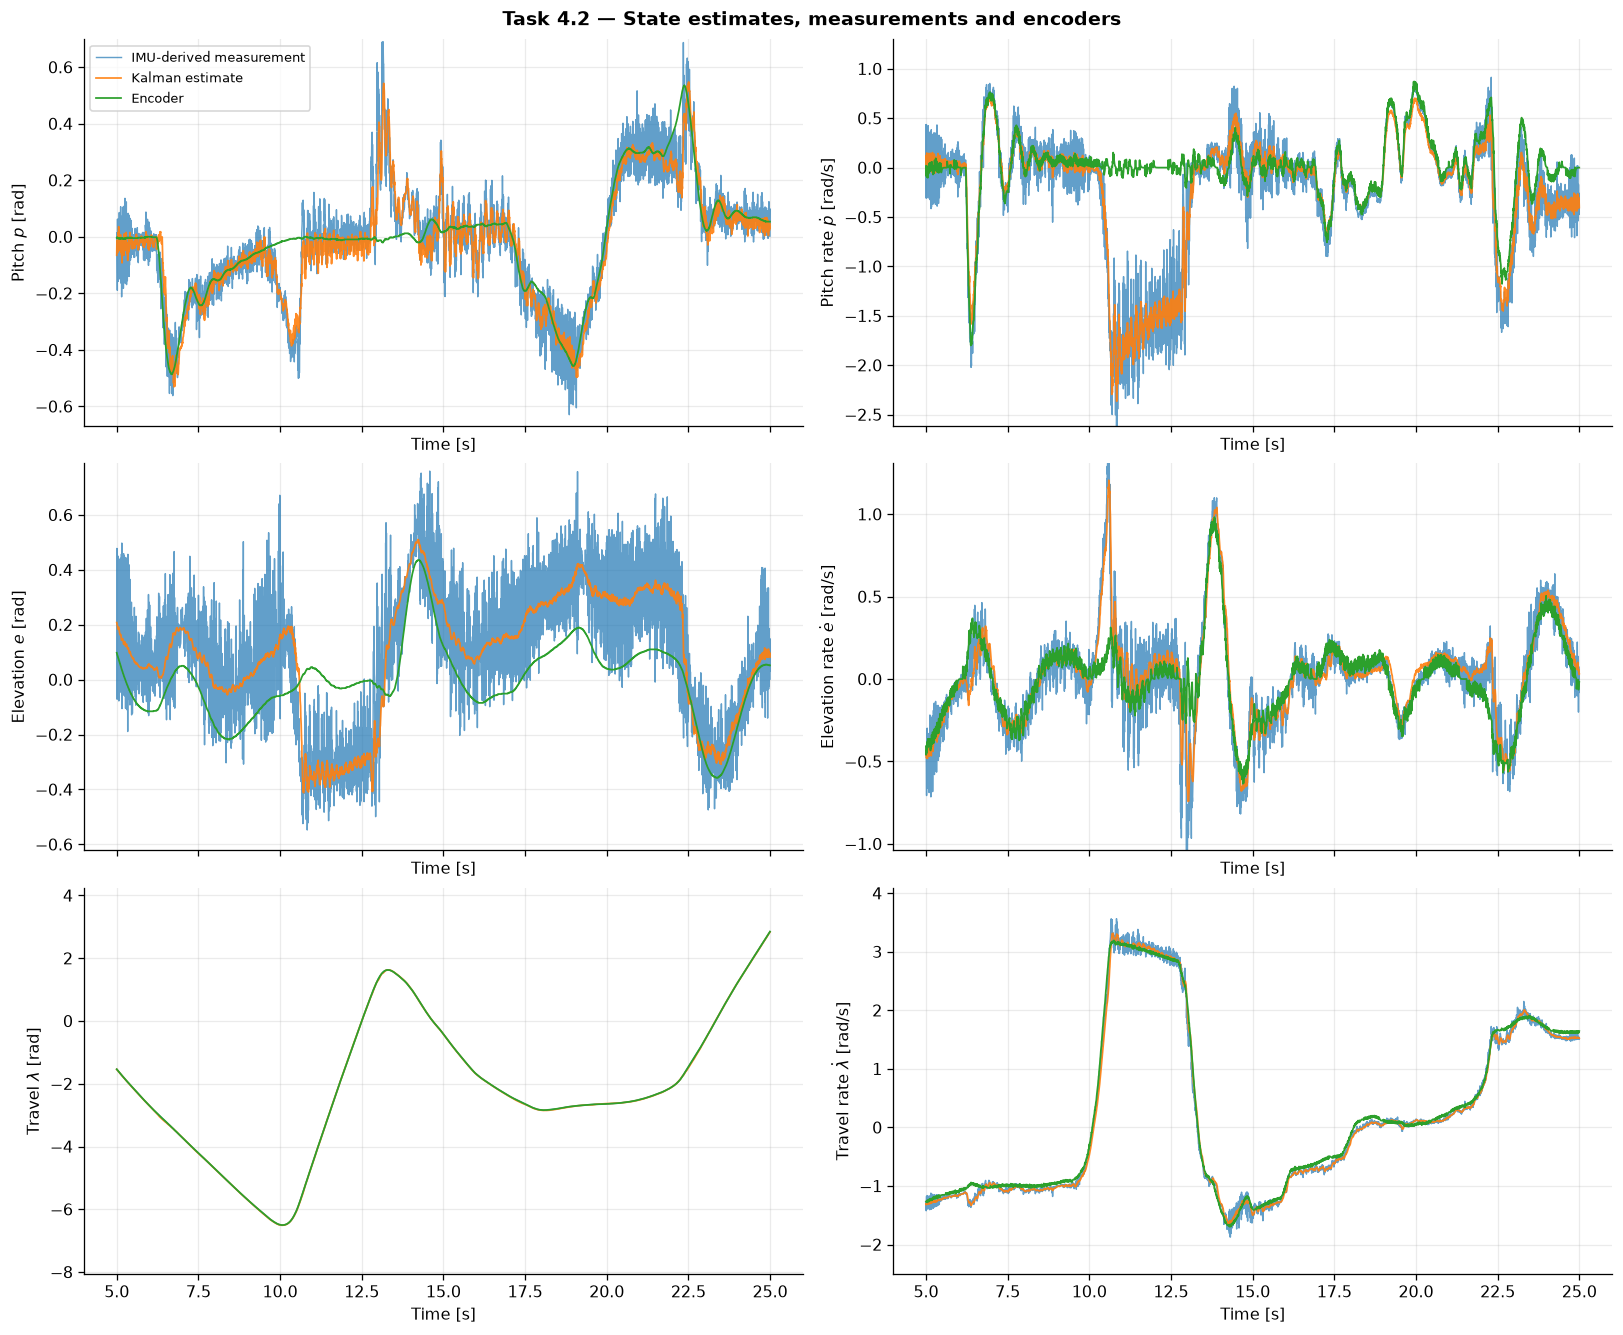

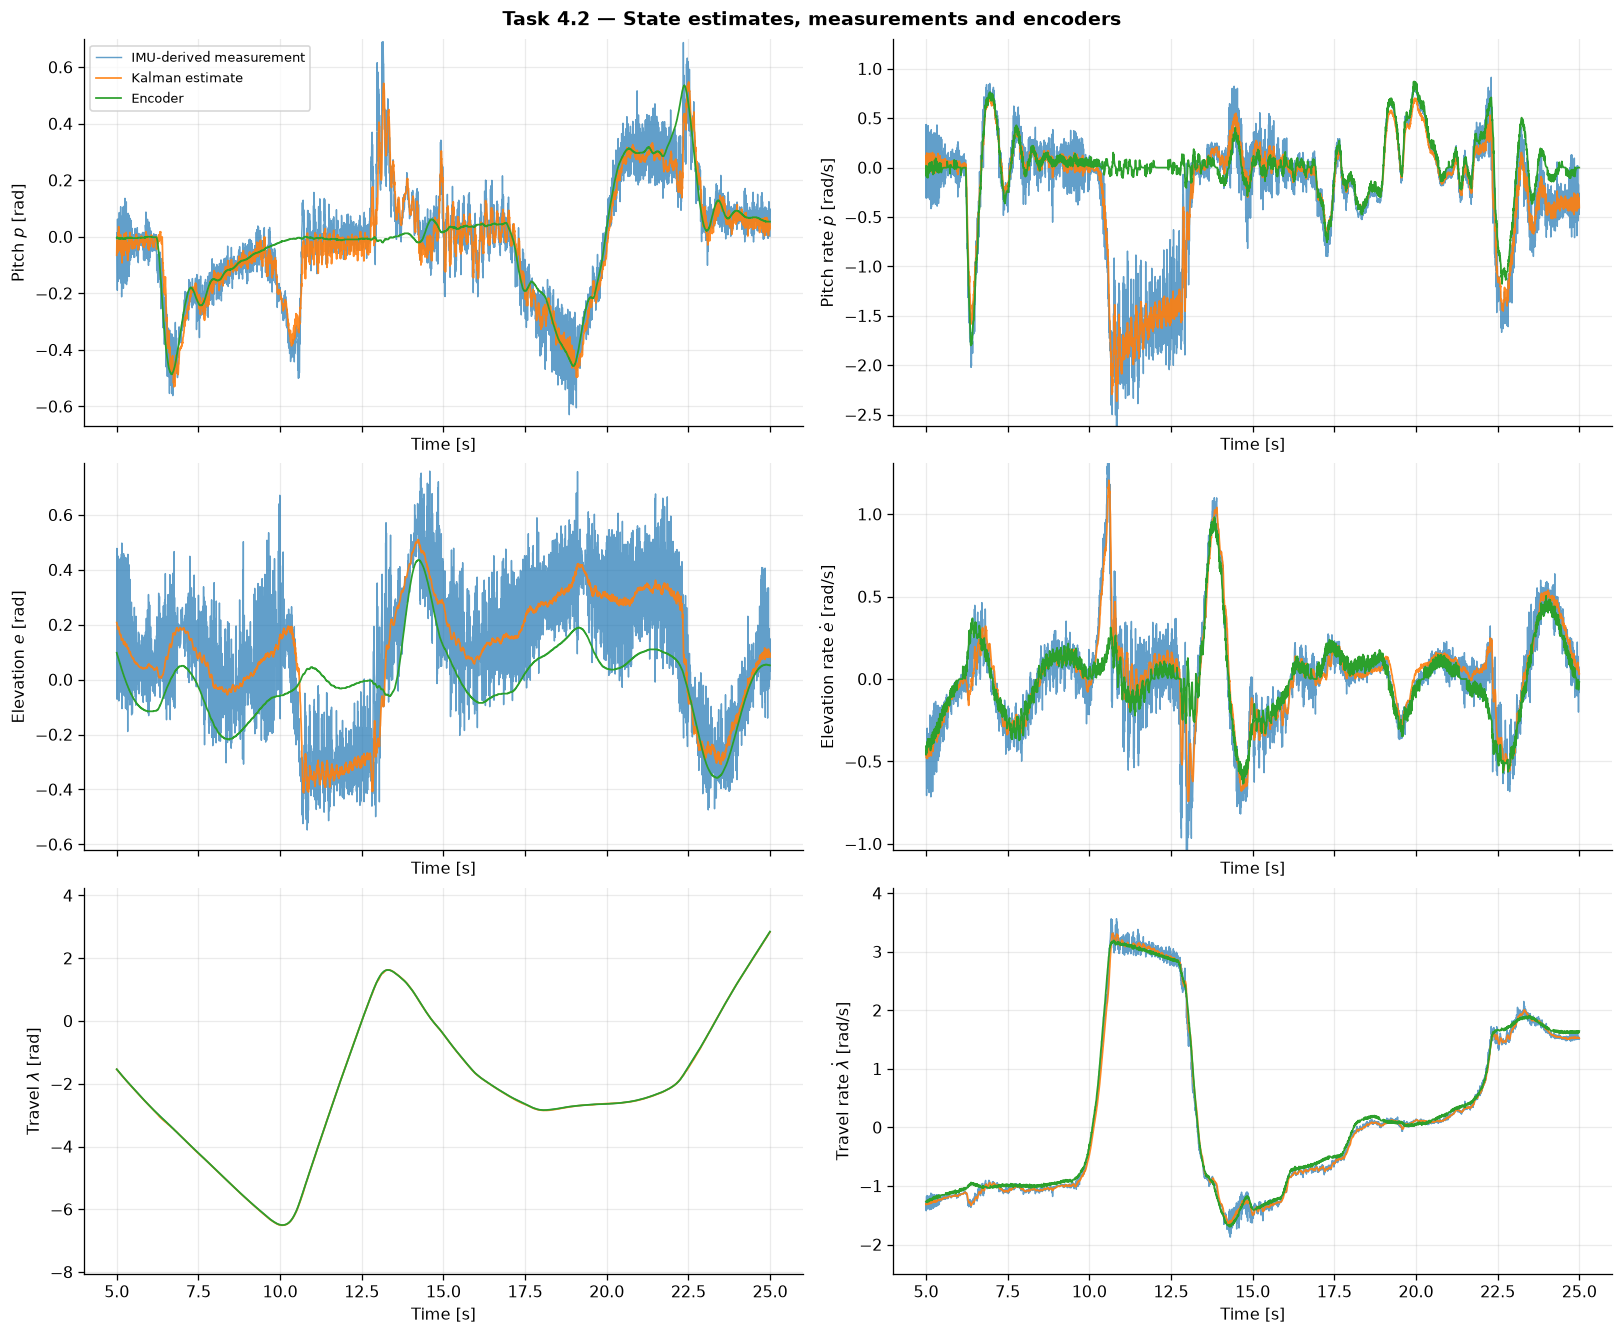

In [34]:
def load_triplet(prefix):
    suffixes = ["_xhatvalues.mat", "_yvalues.mat", "_encodervalues.mat"]
    out = [read_mat(prefix+s) for s in suffixes]
    t0 = out[0][0]
    for tx, dy in out:
        if dy.shape[0] != 6: raise ValueError(f"Expected 6 channels for {prefix}, got {dy.shape}")
        if not np.array_equal(tx,t0):
            raise ValueError(f"Mismatched sample times for {prefix}; do not compare directly")
    return t0, out[0][1], out[1][1], out[2][1]

def plot_triplet(prefix, title=None, save=None, yscale="reference", start=T_START, end=T_END, show=True):
    t, xhat, y, enc = load_triplet(prefix)
    fig, axes = plt.subplots(3, 2, figsize=(14, 11.5), sharex=True)
    tx, xx = view(t, xhat, start, end)
    _, yy = view(t, y, start, end)
    _, ee = view(t, enc, start, end)
    for i, ax in enumerate(axes.flat):
        ax.plot(tx, yy[i], label="Measurement (encoder travel passthrough)" if i==4 else "IMU-derived measurement", lw=0.9, alpha=.7)
        ax.plot(tx, xx[i], label="Kalman estimate", lw=1.1, alpha=.9)
        ax.plot(tx, ee[i], label="Encoder", lw=1.1)
        ax.set_ylabel(f"{STATE_NAMES[i]} [{STATE_UNITS[i]}]")
        if yscale == "reference":
            ref = np.concatenate([ee[i][np.isfinite(ee[i])], yy[i][np.isfinite(yy[i])]])
            if ref.size:
                lo, hi = np.percentile(ref, [.5, 99.5]); delta = max((hi-lo)*.17, .03)
                ax.set_ylim(lo-delta, hi+delta)
                if np.any(np.isfinite(xx[i]) & ((xx[i]<lo-delta) | (xx[i]>hi+delta))):
                    ax.text(.015,.95,"Estimate exceeds displayed range",transform=ax.transAxes,
                            va="top",fontsize=7)
        ax.set_xlabel("Time [s]")
    axes[0,0].legend(loc="best", fontsize=8)
    fig.suptitle(title or prefix, weight="bold")
    if save: save_fig(fig, save)
    if show: plt.show()
    else: plt.close(fig)
    return fig

plot_triplet("task42_newdata", title="Task 4.2 — State estimates, measurements and encoders",
             save="42_baseline_threeway", start=5, end=25)

In [29]:
# Inspect a simple residual summary for the Task 4.2 recording.
t, xhat, y, enc = load_triplet("task42_newdata")
mask = (t >= 2) & np.all(np.isfinite(xhat), axis=0) & np.all(np.isfinite(enc), axis=0)
rmse = np.sqrt(np.mean((xhat[:, mask] - enc[:, mask])**2, axis=1))
display(pd.DataFrame({"State":STATE_LABELS,"Unit":STATE_UNITS,
                      "Estimate vs encoder RMSE":rmse}))

# The additional recordings named task42_tune* lack paired y/encoder files.
# Plot channels separately rather than treating them as directly comparable to the baseline.
additional_42 = sorted(n for n in inventory_df["MAT filename"] if n.startswith("task42_") and "newdata" not in n)
print("Other Task 4.2 recordings:", additional_42)
if EXPORT_TASK42_TUNING:
    for name in additional_42:
        plot_channels(name, "Task 4.2 — "+name+" (channel identity and units unverified)",
                      save="42_"+name.replace(".mat",""), show=False)
print("Standalone Task 4.2 channel identity/units unverified; labels are conservative.")


,State,Unit,Estimate vs encoder RMSE
0,p,rad,0.085100
1,p_dot,rad/s,0.298763
2,e,rad,0.178757
3,e_dot,rad/s,0.106663
4,lambda,rad,0.007941
5,lambda_dot,rad/s,0.091176


Other Task 4.2 recordings: ['task42_qvtuning.mat', 'task42_qvtuningqv10emin6.mat', 'task42_qvtuningqv10emin6__older_v1.mat', 'task42_tuneqd.mat', 'task42_tunigqvexpermient.mat', 'task42_tuningqv.mat']
Figure exported: 42_task42_qvtuning (.png, .pdf)
Figure exported: 42_task42_qvtuningqv10emin6 (.png, .pdf)
Figure exported: 42_task42_qvtuningqv10emin6__older_v1 (.png, .pdf)
Figure exported: 42_task42_tuneqd (.png, .pdf)
Figure exported: 42_task42_tunigqvexpermient (.png, .pdf)
Figure exported: 42_task42_tuningqv (.png, .pdf)
Standalone Task 4.2 channel identity/units unverified; labels are conservative.


### 4.2.1 — Within-trial measurement error versus Kalman estimation error

A fairer, more interpretable diagnostic than comparing RMSE across unrelated trajectories is to use the **same recorded trial** for both raw IMU-derived measurement and Kalman estimate, each compared against encoders. Encoders are an approximate reference, **not absolute ground truth**. The travel angle \(\lambda\) is excluded because it is a direct encoder passthrough into the measurement vector; its measurement error is zero by construction. Below, a ratio under 1 means the estimator has lower RMSE in this particular run; over 1 means worse.

,state,unit,measurement vs encoder RMSE,estimate vs encoder RMSE,estimate / measurement RMSE
0,p,rad,0.101134,0.085100,0.841462
1,p_dot,rad/s,0.337560,0.298763,0.885068
2,e,rad,0.235563,0.178757,0.758850
3,e_dot,rad/s,0.161300,0.106663,0.661273
4,lambda_dot,rad/s,0.096547,0.091176,0.944366


Figure exported: 42_same_trial_residuals (.png, .pdf)


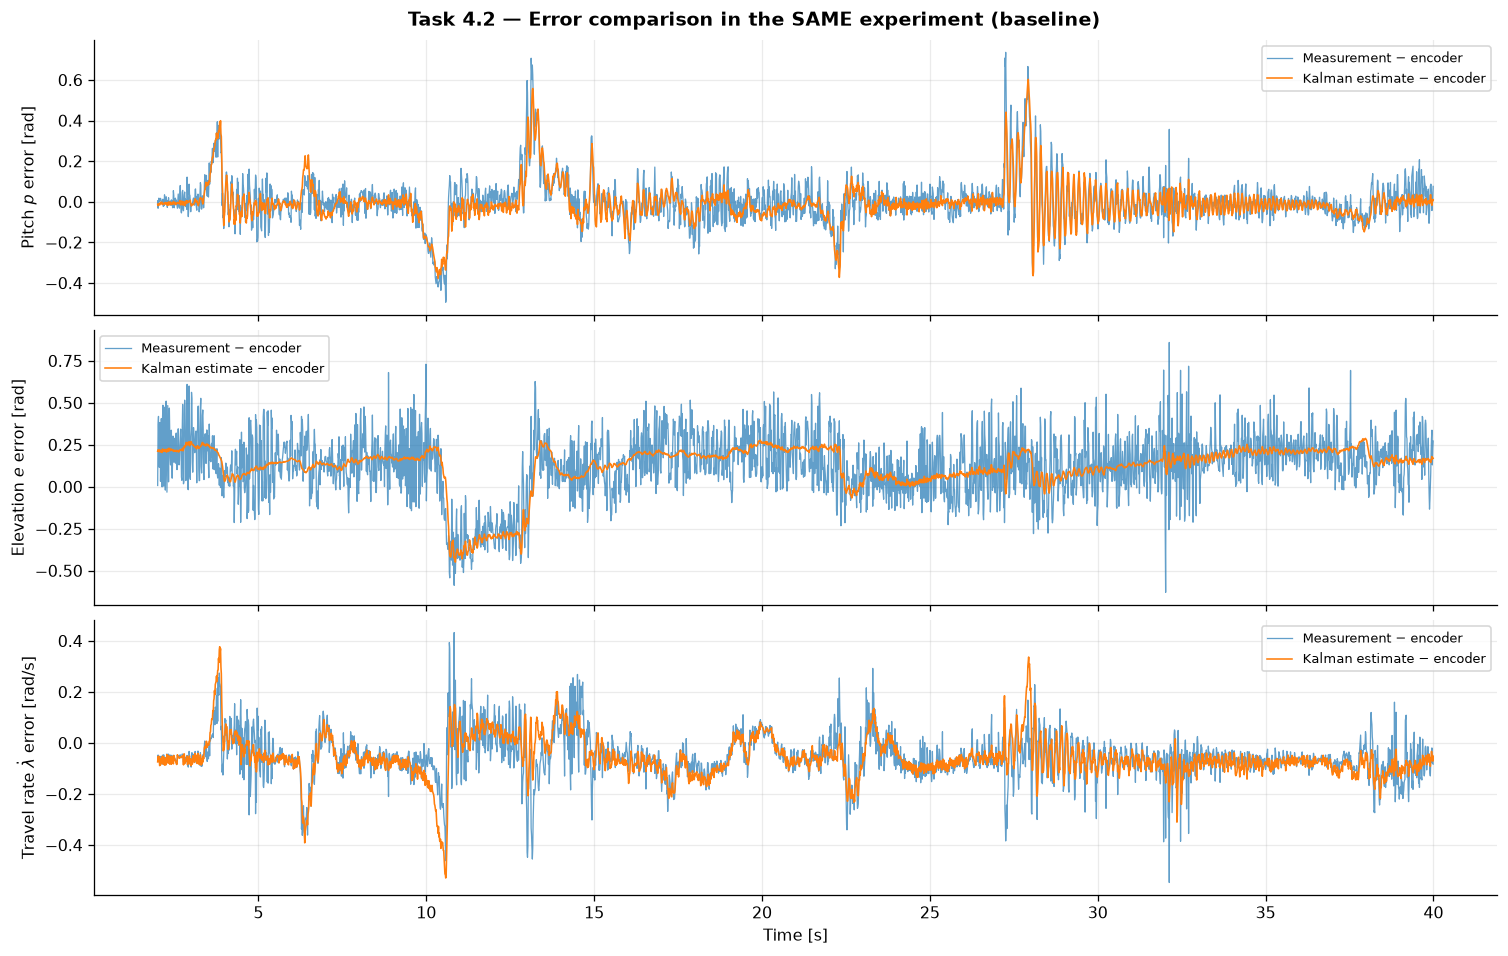

In [30]:
def stable_rmse(error):
    err=np.asarray(error,float)
    err=err[np.isfinite(err)]
    if err.size < 10: return np.nan
    scale=np.max(np.abs(err))
    if scale==0: return 0.0
    return float(scale*np.sqrt(np.mean((err/scale)**2)))

t,xhat,y,enc=load_triplet("task42_newdata")
state_selection=[0,1,2,3,5] # encoder travel-angle passthrough excluded
rows_baseline=[]
for i in state_selection:
    mask=(t>=2.0)&np.isfinite(xhat[i])&np.isfinite(y[i])&np.isfinite(enc[i])
    m_rmse=stable_rmse(y[i,mask]-enc[i,mask])
    k_rmse=stable_rmse(xhat[i,mask]-enc[i,mask])
    rows_baseline.append({"state":STATE_LABELS[i],"unit":STATE_UNITS[i],
           "measurement vs encoder RMSE":m_rmse,"estimate vs encoder RMSE":k_rmse,
           "estimate / measurement RMSE":k_rmse/m_rmse if m_rmse>0 else np.nan})
baseline_df=pd.DataFrame(rows_baseline)
display(baseline_df)
baseline_df.to_csv(OUT/"42_within_trial_errors.csv",index=False)

fig,axes=plt.subplots(3,1,figsize=(13,8.2),sharex=True)
for ax,i in zip(axes,[0,2,5]):
    mask=(t>=2)&(t<=min(40.,t[-1]))
    tx=t[mask]; ii=np.flatnonzero(mask)[::max(1,int(np.ceil(mask.sum()/3500)))]
    ax.plot(t[ii],y[i,ii]-enc[i,ii],label="Measurement − encoder",lw=.8,alpha=.7)
    ax.plot(t[ii],xhat[i,ii]-enc[i,ii],label="Kalman estimate − encoder",lw=1)
    ax.set_ylabel(f"{STATE_NAMES[i]} error [{STATE_UNITS[i]}]")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("Time [s]")
fig.suptitle("Task 4.2 — Error comparison in the SAME experiment (baseline)",weight="bold")
save_fig(fig,"42_same_trial_residuals")
plt.show()

### 4.2.2 — Model parameter consistency

This is a source-code audit, **not** a correction to previously measured helicopter trajectories. The newest initialization script defines the elevation parameter \(K_2\) with a denominator that differs from \(J_e=m_c l_c^2+2m_p l_h^2\) in the preparation handout. Changing the parameter now cannot retroactively correct past results. The experiment-specific tuning values \(Q_d\) are also not stored in the MAT measurement arrays, so filenames are not independent verification of numerical tuning.

**Saved final Simulink configuration:** Inspect the switch that gates IMU `new_data`. The latest saved model reflects the final `nonewdata` test and may not be in a ready-to-fly configuration for the evaluation. Its input selection must be checked in Simulink before running the physical helicopter.


In [31]:
init_files=[p for p in archive.namelist() if p == "Model_reference/init_heli_3_10.m"]
if len(init_files)!=1: raise RuntimeError("Cannot unambiguously identify newest initialization script")
init_source=archive.read(init_files[0]).decode("latin-1")
physical={}
for name in ["g","l_c","l_h","l_p","m_c","m_p","Vs0"]:
    pattern=rf"^\s*{re.escape(name)}\s*=\s*([-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*;"
    match=re.search(pattern,init_source,flags=re.MULTILINE)
    if not match: raise ValueError(f"Cannot parse physical model parameter {name}")
    physical[name]=float(match.group(1))
g,lc,lh,mp,mc,Vs0=(physical[k] for k in ["g","l_c","l_h","m_p","m_c","Vs0"])
Kf=-g*(lc*mc-2*lh*mp)/(lh*Vs0)
Je=mc*lc**2+2*mp*lh**2
K2_theory=Kf*lh/Je
K2_in_init=Kf*lh/(mc*lc**2+2*mp*lh)
assert "K2 = Kf*l_h/((m_c*l_c^2 + 2*m_p*l_h))" in init_source, "Initialization changed: recheck expression manually"
model_diagnostic=pd.DataFrame([
    {"item":"K2 used by latest init file", "value":K2_in_init,"unit":"rad/s² per V"},
    {"item":"K2 expected from preparation Je", "value":K2_theory,"unit":"rad/s² per V"},
    {"item":"(implemented / expected) - 1", "value":K2_in_init/K2_theory-1,"unit":"fraction"},
])
display(model_diagnostic)
model_diagnostic.to_csv(OUT/"42_model_parameter_audit.csv",index=False)
print("Stored init Qd assignment ends in Qd = Qd*1E-1; it is a FINAL config, not proof of earlier trial values.")
# Inspect the saved Simulink switch controlling new_data, without executing or modifying .slx.
import xml.etree.ElementTree as ET
model_files=[p for p in archive.namelist() if p.endswith("/heli_q8.slx") and PREFERRED_FOLDER.lower() in p.lower()]
if len(model_files)!=1: raise RuntimeError("Saved Simulink model is ambiguous")
with zipfile.ZipFile(BytesIO(archive.read(model_files[0]))) as model:
    model_root=ET.fromstring(model.read("simulink/systems/system_root.xml"))
def get_block(block_sid):
    return next(b for b in model_root.iter("Block") if b.get("SID")==block_sid)
def prop(block,prop_name):
    return next((p.text for p in block.findall("P") if p.get("Name")==prop_name),None)
switch=get_block("479")
assert switch.get("BlockType")=="Switch"
selector=get_block("481")
assert selector.get("BlockType")=="Constant"
selector_value=prop(selector,"Value")
bottom=get_block("480")
bottom_value=prop(bottom,"Value")
criterion=prop(switch,"Criteria")
print(f"Latest model new_data selector: constant={selector_value}, criterion={criterion}, fallback constant={bottom_value}.")
print("With the default Switch Threshold=0, this configuration routes a constant zero to the Kalman filter.")
print("Check settings before oral demonstration: archived model shows final nonewdata configuration, not all recorded trials.")
pd.DataFrame([{"Item":"Switch criterion","Saved setting":criterion},
              {"Item":"Switch control input (SID 481)","Saved setting":selector_value},
              {"Item":"Switch fallback input (SID 480)","Saved setting":bottom_value},
              {"Item":"Threshold property explicitly stored","Saved setting":str(prop(switch,"Threshold") is not None)}
             ]).to_csv(OUT/"42_saved_newdata_switch_audit.csv",index=False)


,item,value,unit
0,K2 used by latest init file,0.064789,rad/s² per V
1,K2 expected from preparation Je,0.085046,rad/s² per V
2,(implemented / expected) - 1,-0.238183,fraction


Stored init Qd assignment ends in Qd = Qd*1E-1; it is a FINAL config, not proof of earlier trial values.


RuntimeError: Saved Simulink model is ambiguous

## 4.3 — Task 3: Experiments with process-noise covariance \(Q_d\)

The filenames describe combinations of `newdata` (measurement correction enabled) / `nonewdata` (correction disabled), and several candidate \(Q_d\) choices. Each combination is a **different physical experiment**. In particular, different control inputs and movements prevent interpreting across-run RMS differences as isolated effects of \(Q_d\).

We first enumerate complete triplets, then inspect a selected case. *Qd names below are archive identifiers*, not guaranteed numerical runtime values; e.g. the latest initialization file multiplies its diagonal \(10^{34}\) entries by \(10^{-1}\).

In [ ]:
cases = {}
for mode in ("newdata", "nonewdata"):
    for qd in ("qd0", "qdemin6", "qdemin4", "qde1", "qde34", "qdinf"):
        prefix=f"task43_{mode}_{qd}"
        try:
            t, xhat, y, enc = load_triplet(prefix)
            cases[(mode,qd)] = prefix
        except FileNotFoundError:
            pass
print("Available complete experiment triplets:")
display(pd.DataFrame([{"measurement mode":k[0],"Qd file tag":k[1],"prefix":v}
                      for k,v in cases.items()]))
print("NOTE: qdinf/nonewdata is not present in the archive.")
selected = cases.get((SELECTED_MODE,SELECTED_QD))
if selected is None:
    raise ValueError(f"No complete recording for mode={SELECTED_MODE}, Qd={SELECTED_QD}")
plot_triplet(selected, title=f"Task 4.3 — {SELECTED_MODE}, {SELECTED_QD}",
             save=f"43_{SELECTED_MODE}_{SELECTED_QD}_threeway")

In [ ]:
def case_metrics(prefix, min_time=2.0):
    t, xhat, y, enc = load_triplet(prefix)
    time_mask = t >= min_time
    finite = np.isfinite(xhat) & np.isfinite(enc)
    all_ok = finite & time_mask[None,:]
    row = {"case":prefix, "duration [s]":t[-1]}
    row["estimate finite [%]"] = float(100 * np.isfinite(xhat).mean())  # full recording
    row["estimate finite t>=2s [%]"] = float(100 * np.isfinite(xhat[:,time_mask]).mean())
    for i, label in enumerate(STATE_LABELS):
        valid = all_ok[i]
        if valid.sum() == 0:
            row[f"RMSE {label}"] = np.nan
        else:
            err = np.abs(xhat[i, valid] - enc[i, valid])
            # Scaling prevents overflow during squaring for extremely large values.
            scale = max(np.max(err),1e-300)
            row[f"RMSE {label}"] = float(scale * np.sqrt(np.mean((err/scale)**2)))
    return row

rows = []
for (mode,qd), prefix in cases.items():
    row = case_metrics(prefix)
    row.update({"mode":mode,"Qd tag":qd})
    rows.append(row)
metrics = pd.DataFrame(rows)
cols = ["mode","Qd tag","duration [s]","estimate finite [%]","estimate finite t>=2s [%]"] + [f"RMSE {x}" for x in STATE_LABELS]
display(metrics[cols].sort_values(["mode","Qd tag"]).reset_index(drop=True))
metrics[cols].to_csv(OUT / "43_experiment_RMSE.csv", index=False)

### 4.3.1 — Within-run normalized performance across all experiments

For each experiment, compare Kalman estimation RMSE and its own IMU-derived measurement RMSE against the **same** encoder trace. The ratio has no units and avoids mixing angular position with angular rate. This is descriptive; trajectories still differ between trials, and there is no identical-input A/B test. Encoder travel \(\lambda\) is excluded because its measured value is copied directly from the encoder. A ratio below one indicates lower estimation RMSE; above one indicates higher error. `N/A` means insufficient finite post-startup samples.

In [ ]:
performance=[]
for (mode,qd),prefix in cases.items():
    t,xhat,y,enc=load_triplet(prefix)
    for idx in [0,1,2,3,5]:
        m=(t>=2.0) & np.isfinite(xhat[idx]) & np.isfinite(y[idx]) & np.isfinite(enc[idx])
        rm=stable_rmse(y[idx,m]-enc[idx,m])
        rk=stable_rmse(xhat[idx,m]-enc[idx,m])
        performance.append({"mode":mode,"Qd tag":qd,"state":STATE_LABELS[idx],"unit":STATE_UNITS[idx],
                            "usable samples":int(m.sum()),"measurement RMSE":rm,"estimate RMSE":rk,
                            "estimate / measurement":rk/rm if (np.isfinite(rk) and np.isfinite(rm) and rm>0) else np.nan})
perf_df=pd.DataFrame(performance)
perf_df.to_csv(OUT/"43_within_trial_comparison.csv",index=False)
order=[("newdata",q) for q in ["qd0","qdemin6","qdemin4","qde1","qde34","qdinf"]]+[
    ("nonewdata",q) for q in ["qd0","qdemin6","qdemin4","qde1","qde34"]]
cols=[STATE_LABELS[i] for i in [0,1,2,3,5]]
heat=np.full((len(order),len(cols)),np.nan)
for r,(mode,qd) in enumerate(order):
    for k,state in enumerate(cols):
        subset=perf_df[(perf_df["mode"]==mode)&(perf_df["Qd tag"]==qd)&(perf_df["state"]==state)]
        if not subset.empty: heat[r,k]=subset["estimate / measurement"].iloc[0]
logs=np.where(heat>0,np.log10(heat),np.nan)
fig,ax=plt.subplots(figsize=(11,6.3))
from matplotlib.colors import TwoSlopeNorm
img=ax.imshow(np.ma.masked_invalid(logs),aspect="auto",cmap="coolwarm",norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=5))
ax.set_xticks(range(len(cols)),cols)
ax.set_yticks(range(len(order)),[m+" / "+q for m,q in order])
for r in range(len(order)):
    for k in range(len(cols)):
        val=heat[r,k]
        if np.isfinite(val):
            lab=f"{val:.3g}"
        else: lab="N/A"
        ax.text(k,r,lab,ha="center",va="center",fontsize=7,
                color="white" if np.isfinite(logs[r,k]) and logs[r,k]>3.0 else "black")
fig.colorbar(img,ax=ax,label="log10(Kalman RMSE / measurement RMSE) [-]")
ax.set_title("Task 4.3 — Per-trial estimate/measurement error ratio (encoder reference)")
ax.set_xlabel("State (travel angle excluded: encoder passthrough)")
save_fig(fig,"43_within_trial_error_ratio")
plt.show()
print("NOTE: A ratio >1 means worse estimate-to-encoder RMSE in this recording, not a general failure of Kalman filtering.")

### 4.3.2 — Comparing \(Q_d\) regimes

This summary uses logarithmic axes to accommodate dramatically different errors. All error values are calculated from the **unclipped original data**, not from axis-limited figures. `NaN`-dominated runs appear separately through their fraction of finite estimates. The units for the six RMS values differ; therefore, only compare the *same* state across runs.

In [ ]:
qd_order = ["qd0", "qdemin6", "qdemin4", "qde1", "qde34", "qdinf"]
fig, axes = plt.subplots(1, 3, figsize=(15,4.8), sharey=False)
for ax, ind in zip(axes, [0,2,5]):
    for mode in ("newdata", "nonewdata"):
        temp=metrics[metrics["mode"]==mode].set_index("Qd tag")
        q=[x for x in qd_order if x in temp.index]
        vals=np.array([temp.loc[x,f"RMSE {STATE_LABELS[ind]}"] for x in q],dtype=float)
        ax.plot(q,vals,marker="o",label="Updates enabled" if mode == "newdata" else "Updates disabled")
    ax.set_yscale("log")
    ax.set_title(f"{STATE_NAMES[ind]} [{STATE_UNITS[ind]}]")
    ax.set_ylabel(f"Estimate-to-encoder RMSE [{STATE_UNITS[ind]}] (log scale)")
    ax.set_xlabel("$Q_d$ experiment (filename tag)")
    ax.tick_params(axis="x",rotation=35)
    # Explicitly show all tested filename tags; qdinf has no valid post-2 s RMSE.
    ax.set_xticks(qd_order)
    ax.set_xlim(-0.4, len(qd_order)-0.6)
    ax.text(5, 0.04, "N/A", ha="center", va="bottom", fontsize=8,
            transform=ax.get_xaxis_transform())
axes[0].legend()
fig.suptitle("Task 4.3 — Error summaries by experiment (different trajectories)", weight="bold")
save_fig(fig,"43_rmse_overview")
plt.show()

fig, ax = plt.subplots(figsize=(10,4.2))
for mode in ("newdata", "nonewdata"):
    temp=metrics[metrics["mode"]==mode].set_index("Qd tag")
    q=[x for x in qd_order if x in temp.index]
    ax.plot(q,[temp.loc[x,"estimate finite [%]"] for x in q],marker="o",label="Updates enabled" if mode == "newdata" else "Updates disabled")
ax.set_ylim(-3,103)
ax.set_ylabel("Finite state estimates [%]")
ax.set_xlabel("$Q_d$ experiment (filename tag)")
ax.set_title("Task 4.3 — Numerical validity across the recording")
ax.legend()
save_fig(fig,"43_finite_fraction")
plt.show()

### 4.3.3 — Measurement dropout versus regular updates

The `nonewdata` files represent runs with the correction channel disconnected. Below, **each run is compared against its own encoder recording**, not against a different joystick trajectory.

In [ ]:
def compare_measurement_modes(qd="qdemin6", state_index=2):
    fig,axes=plt.subplots(2,1,figsize=(12,6.4),sharex=False)
    for ax, mode in zip(axes,["newdata","nonewdata"]):
        prefix=cases.get((mode,qd))
        if prefix is None:
            ax.text(.5,.5,"Unavailable",ha="center");continue
        t,xhat,y,enc=load_triplet(prefix)
        tx,xx=view(t,xhat); _,ee=view(t,enc)
        ax.plot(tx,ee[state_index],label="Encoder",lw=1)
        ax.plot(tx,xx[state_index],label="Kalman estimate",lw=1)
        ax.set_title(f"{mode} — {qd}, duration {t[-1]:.1f} s")
        ax.set_ylabel(f"{STATE_NAMES[state_index]} [{STATE_UNITS[state_index]}]")
        ax.set_xlabel("Time [s]")
        ax.legend()
    fig.suptitle("Task 4.3 — Effect of enabling/disabling measurement correction",weight="bold")
    save_fig(fig,f"43_dropout_{qd}_{STATE_LABELS[state_index]}")
    plt.show()
    return fig

compare_measurement_modes("qdemin6", state_index=2)  # elevation

### 4.3.4 — Error growth when measurement correction is disabled

To make drift visible even when its magnitude exceeds the reference-limited state plots, show the magnitude of estimation error on a logarithmic scale. These are **separate helicopter flights**, not a continuous switch-off/switch-on experiment. The plotted curves must not be interpreted as time-aligned replications.

In [ ]:
fig,axs=plt.subplots(3,1,figsize=(12.5,8.0),sharex=False)
for ax,i in zip(axs,[0,2,5]):
    for mode in ("newdata","nonewdata"):
        prefix=cases.get((mode,"qdemin6"))
        if prefix is None: continue
        tt,xx,yy,ee=load_triplet(prefix)
        sel=np.flatnonzero((tt>=2.0)&(tt<=min(tt[-1],60.0)))
        sel=sel[::max(1,int(np.ceil(len(sel)/3000)))]
        err=np.abs(xx[i,sel]-ee[i,sel])
        err=np.where((err>0)&np.isfinite(err),err,np.nan)
        ax.semilogy(tt[sel],err,label="Updates enabled" if mode=="newdata" else "Updates disabled",lw=1.0)
    ax.set_ylabel(f"|{STATE_LABELS[i]} estimate − encoder| [{STATE_UNITS[i]}]")
    ax.set_xlabel("Time since start of each separate run [s]")
    ax.legend(fontsize=8)
fig.suptitle("Task 4.3 — Error growth under separate update/no-update trials (Qd tag: qdemin6)",weight="bold")
save_fig(fig,"43_update_dropout_log_error")
plt.show()

### 4.3.5 — Numerical breakdown at extreme \(Q_d\)

The recording named `qdinf` contains non-finite estimates. We explicitly find the **first invalid sample**, rather than drawing a misleading continuous trace or using non-finite values as numerical data. The `qd0` experiment should also be viewed carefully: a zero initial covariance and zero process covariance can prevent the filter from accepting new measurements.

The **finite-estimate percentage** is calculated over the complete recording. RMSE, by contrast, is calculated from $t\geq2\,\mathrm{s}$ where estimates are finite; if there are no valid samples, it is undefined rather than zero.


In [ ]:
if ("newdata","qdinf") in cases:
    t,xhat,y,enc = load_triplet(cases[("newdata","qdinf")])
    failure = np.flatnonzero(~np.all(np.isfinite(xhat),axis=0))
    if failure.size:
        k=int(failure[0])
        print(f"qdinf: first non-finite state estimate at t = {t[k]:.3f} s (sample {k}).")
        j=min(k+20,len(t))
        fig, axes = plt.subplots(3, 1, figsize=(10,7.8), sharex=True)
        for ax, i in zip(axes, [0,2,5]):
            ax.plot(t[:j],xhat[i,:j],label="Kalman estimate",lw=1)
            ax.plot(t[:j],enc[i,:j],label="Encoder",lw=.9,alpha=.75)
            ax.axvline(t[k],linestyle="--",color="gray",label="First non-finite estimate")
            ax.set_ylabel(f"{STATE_NAMES[i]} [{STATE_UNITS[i]}]")
            ax.legend(loc="best",fontsize=8)
        axes[-1].set_xlabel("Time [s]")
        fig.suptitle("Task 4.3 — qdinf: onset of numerical breakdown",weight="bold")
        save_fig(fig,"43_qdinf_first_nonfinite")
        plt.show()
    else:
        print("qdinf record remains finite for entire duration")

### 4.3.6 — Complete figure export

`EXPORT_ALL_CASES = True` in the configuration cell exports a **six-state figure for every complete experiment**, even when estimates diverge. The `reference` y-axis choice prevents a failed estimate from making all physical signals unreadable; out-of-range estimator values are **annotated, not silently removed from calculations**.

In [ ]:
if EXPORT_ALL_CASES:
    old_pdf, old_max = EXPORT_PDF, SHOW_MAX_POINTS
    EXPORT_PDF, SHOW_MAX_POINTS = False, 1500  # faster bulk export; PNG only
    try:
        for (mode, qd), prefix in cases.items():
            plot_triplet(prefix, title=f"Task 4.3 — {mode}, {qd}",
                         save=f"43_{mode}_{qd}_threeway", yscale="reference", show=False)
    finally:
        EXPORT_PDF, SHOW_MAX_POINTS = old_pdf, old_max
else:
    print("Set EXPORT_ALL_CASES=True in section 0 to save PNGs for every available experiment.")

## 4.5 — Task 5: Evaluation-ready comparisons

Prepare representative figures with all six states, encoder references, IMU-based measurements and Kalman-filter estimates. Suggested discussion:

1. Highlight one **nominal** measurement-updated run (six-panel plot).
2. Show sensitivity to \(Q_d\) and explain why increasing assumed process uncertainty generally increases the weight placed on incoming measurements (subject to finite covariance and valid noise assumptions).
3. Show a **no-measurement** run and explain propagation of \(\bar x\) and \(\bar P\) without a corrective update.
4. Document that the recordings provided here do **not** include a saved time series of the Kalman covariance matrix \(P\). The state-estimation difference relative to the encoders **is not** the same as \(P\). A plot of \(P\) requires a recorded signal or a separately validated replay of the filter with the correct recorded control inputs and update flags.

The figure directory contains vector-friendly PDF exports alongside PNG previews.

In [ ]:
# Compact presentation figure: selected nominal run, three most illustrative states.
selected_prefix = cases.get(("newdata","qdemin6"),"task42_newdata")
t,xhat,y,enc=load_triplet(selected_prefix)
fig,axes=plt.subplots(3,1,figsize=(11,8.4),sharex=True)
tx,xx=view(t,xhat);_,yy=view(t,y);_,ee=view(t,enc)
for ax,i in zip(axes,[0,2,5]):
    ax.plot(tx,ee[i],label="Encoder",lw=1.15)
    ax.plot(tx,yy[i],label="IMU-derived measurement",lw=.9,alpha=.7)
    ax.plot(tx,xx[i],label="Kalman estimate",lw=1.1)
    ax.set_ylabel(f"{STATE_NAMES[i]} [{STATE_UNITS[i]}]")
    ax.legend(loc="best",fontsize=8)
axes[-1].set_xlabel("Time [s]")
fig.suptitle("Task 4.5 — Demonstration figure: pitch, elevation and travel rate",weight="bold")
save_fig(fig,"45_presentation_summary")
plt.show()

## 4.6 — Task 6: Oral evaluation — evidence checklist

- Explain **prediction → new IMU data? → correction/no correction → next prediction** and the fixed sample time, \(T_s=0.002\,\mathrm{s}\).
- State how \(R_d\) was estimated from actual measurement samples, and what parts of its variability may be helicopter motion rather than sensor noise.
- Explain why \(Q_d\) trades responsiveness against noise suppression, and why zero/extreme \(Q_d\) cases can perform poorly or become numerically invalid.
- Use encoder measurements as a reference with known caveats; clarify that travel angle can be encoder-derived in the measurement vector.
- Explain how Luenberger pole-placement differs from choosing a Kalman gain based on covariance assumptions.
- Keep the Simulink/Matlab files and joystick-compatible setup available separately for the lab demonstration; this notebook is for **offline analysis**, not hardware deployment.

### Files generated

The notebook saved all figures in `figures_lab4/`; PNG and PDF versions have identical content. To archive results in Python after execution:

**Fourth audit oral-discussion checklist:**

- Explain why \(Q_d=0\) with \(P_0=0\) may prevent incorporation of measurements: the Kalman gain stays zero in the ideal recursion.
- Point out the actual initialization-file \(K_2\) mismatch and its possible impact on model-based prediction, without retroactively changing the recorded data.
- Clarify that \(R_d\) estimated from an unsteady flight segment mixes motion and measurement noise, and that repeated IMU samples mean 2 ms samples are not independent.
- Distinguish separate `newdata` / `nonewdata` recordings from switching the correction input during **one continuous experiment**; the latter is not demonstrated by saved logs.
- State explicitly that \(P[k]\), the `new_data` bit, and experiment-specific \(Q_d\) / \(R_d\) metadata were not logged in the measurement files. Physical \(P[k]\) curves cannot be recovered uniquely from these data.
- Do not claim a quantitative Kalman-versus-Luenberger comparison: the available Lab 3 time-series are not matched to these trials. Discuss differences theoretically instead.

- Before the oral demo, verify the saved `new_data` switch and rebuild if necessary: the final archived configuration appears to force correction off (two constant-zero inputs at the gate, standard threshold 0).


In [ ]:
saved = sorted(OUT.glob("*.png"))
print(f"{len(saved)} PNG figures created in {OUT}")
for p in saved:
    print(" -",p.name)
extra_figures=["41_autocorrelation.png","42_same_trial_residuals.png",
               "43_within_trial_error_ratio.png","43_update_dropout_log_error.png"]
assert all((OUT/f).exists() for f in extra_figures), "Missing fourth-audit figure"


## A. Distinct older recordings in the original ZIP

Two differing older Part IV recordings are included in `Data/Task_4_1/Older_versions/` and `Data/Task_4_2/Older_versions/` with `__older_v1` suffixes. Both versions deserve figures. The older version of `task34_u.mat` also differs, but it belongs to previous-lab material and is not part of this Lab 4 figure set.

This section uses exact paths inside the cleaned Part IV ZIP archive.

The old `heli_q8.slx` directly logs `task42_qvtuningqv10emin6.mat` from the `y-transformer` output. Its six channels can therefore be labeled as \(p,\dot p,e,\dot e,\lambda,\dot\lambda\), with channel five sourced from encoder travel. This verification applies to the **older file only**.


In [ ]:
import hashlib
from collections import defaultdict

content_hash = {p: hashlib.sha256(archive.read(p)).hexdigest() for p in files_in_zip}
nonidentical_older = {}
older_specs = [
    ("Data/Task_4_1/Older_versions/task41_xhat_noie_fligh__older_v1.mat", "41_flight_recording_older"),
    ("Data/Task_4_2/Older_versions/task42_qvtuningqv10emin6__older_v1.mat", "42_task42_qvtuningqv10emin6_older"),
]
for old_path, name in older_specs:
    if old_path not in files_in_zip:
        warnings.warn(f"Missing expected older version: {old_path}")
        continue
    nonidentical_older[old_path] = name + ".png"
    if name.startswith("41_"):
        labels = [f"{s} [{u}] (state order assumed)" for s,u in zip(STATE_NAMES, STATE_UNITS)]
        plot_channels(old_path, "Task 4.1 — Older in-flight 6-channel recording (state order assumed)",
                      labels=labels, save=name, show=False)
    else:
        labels = [f"{s} [{u}]" + (" (encoder passthrough)" if i == 4 else "")
                  for i,(s,u) in enumerate(zip(STATE_NAMES, STATE_UNITS))]
        plot_channels(old_path, "Task 4.2 — Older y-vector (Simulink source verified)",
                      labels=labels, save=name, show=False)
print("Older distinct recordings exported:", list(nonidentical_older))


## A. File-to-figure coverage audit

This is an **explicit audit of all available MAT recordings**. The notebook treats the four `task41_*` filenames, the eight `task42_*` filenames and all 33 `task43_*` filenames as **Lab 4 core**. The original archive contains two additional **different older versions** of Lab 4 recordings with the same basename; those are plotted independently as well. A complete triple of `xhatvalues`, `yvalues`, and `encodervalues` maps to a single six-panel figure.

The six additional files (`task34_*`, `task 31playing`, `task 2b byson`, `taskpocomneg1j10`) are **older lab / ancillary material**, rather than missing Lab 4 files. Task 3's comparison with the Luenberger observer is mainly theoretical; its older recordings cannot be overlaid on the Kalman tests without synchronized experiments and clear matching channels.

A figure's existence only establishes that its raw recording is *represented*; it does **not** independently validate unknown signal names for standalone recordings. All figures use seconds on the horizontal axis. Unknown channel labels deliberately avoid inventing units.


The audit checks each of the 47 distinct *Part IV archive members* and verifies that they are represented by a figure. File identities were independently checked against the original archive in the provided file manifest.


In [ ]:
def figure_for_mat(filename):
    if filename.startswith("task41_"):
        return {
            "task41_noice_grounded.mat": "41_extra_grounded.png",
            "task41_xhat_noie_grounded.mat": "41_grounded_raw.png",
            "task41_xhat_noie_fligh.mat": "41_flight_recording.png",
            "task41_xhat_noie_flight.mat": "41_additional_flight_5ch.png",
        }.get(filename)
    if filename.startswith("task42_newdata_"):
        return "42_baseline_threeway.png"
    if filename.startswith("task42_"):
        return "42_" + filename[:-4] + ".png"
    if filename.startswith("task43_"):
        m = re.match(r"task43_(newdata|nonewdata)_(qd[^_]+)_(xhatvalues|yvalues|encodervalues)\.mat$", filename)
        if m:
            return f"43_{m.group(1)}_{m.group(2)}_threeway.png"
    return None

coverage_rows=[]
for path in sorted(files_in_zip):
    basename=path.rsplit("/",1)[-1]
    newest_path=match_path(basename)
    core=basename.startswith(("task41_","task42_","task43_"))
    different=(path in nonidentical_older)
    duplicate=(path!=newest_path and not different)
    expected=(nonidentical_older.get(path) or figure_for_mat(basename)) if core else None
    t, y=read_mat(path)
    coverage_rows.append({
        "Archive member":path,"MAT filename":basename,"Channels":y.shape[0],
        "Samples":y.shape[1],"Lab 4 core":core,
        "Variant":"different older version" if different else ("identical duplicate" if duplicate else "preferred"),
        "Expected plot":expected,"Plot present": (OUT/expected).is_file() if expected else False,
        "Content SHA-256":content_hash[path],
    })
file_audit=pd.DataFrame(coverage_rows)
file_audit.to_csv(OUT/"00_file_coverage.csv",index=False)
core_audit=file_audit[file_audit["Lab 4 core"]]
print("Lab 4 core archive members:",len(core_audit))
print("Distinct Lab 4 recordings by contents:",core_audit["Content SHA-256"].nunique())
print("Lab 4 core entries represented in exported plots:",int(core_audit["Plot present"].sum()))
print("Non-core files (not required for Lab 4 plot set):",len(file_audit)-len(core_audit))
missing=core_audit[~core_audit["Plot present"]]
if not missing.empty: display(missing)
else: print("PASS — all distinct Lab 4 recordings, including older different versions, are plotted.")
display(file_audit[["MAT filename","Channels","Samples","Lab 4 core","Variant","Expected plot","Plot present"]])
assert missing.empty,"Lab 4 source recordings without exported plot"